# 02 - LimiX-2 scoring and explanations

This notebook fits LimiX-2, LightGBM and logistic regression on the same synthetic cash-flow
portfolio, compares ranking and calibration, and explains individual decisions.

> **Licence:** LimiX-2 weights are non-commercial. The notebook detects whether the checkpoint is
> available and falls back to the tree and linear baselines otherwise. See `docs/limix.md`.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

from opencashflow.data.synthetic import generate_portfolio
from opencashflow.features.cashflow_features import FeatureConfig
from opencashflow.models import (
    LimiXScorer,
    LogisticBaseline,
    TreeBaseline,
    calibration_table,
    evaluate_binary,
    explain_model,
)

pd.set_option("display.width", 140)

## 1. Build a labelled portfolio

We use 120 companies and a two-year feature window. The train/test split is stratified so the default rate is similar in both sets.

In [2]:
portfolio = generate_portfolio(
    n_companies=120,
    months=18,
    default_rate=0.15,
    seed=7,
)
X, y = portfolio.to_features(FeatureConfig(window_days=18 * 31))
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print(portfolio.summary())
print("Train:", X_train.shape, "Test:", X_test.shape, "Default rate:", round(float(y.mean()), 3))

120 companies, 63,410 transactions, default rate 16.7%, 2023-01-02 to 2024-06-29
Train: (84, 151) Test: (36, 151) Default rate: 0.167


## 2. Check LimiX availability

The wrapper resolves the checkpoint from `LIMIX_MODEL_PATH` and the configs from `LIMIX_SRC` / `LIMIX_CONFIG_DIR`. No weights are downloaded automatically.

In [3]:
limix_info = LimiXScorer.availability()
limix_info

{'available': True,
 'model_path': 'C:\\Users\\youss\\Documents\\Code\\tabularFM_tests\\cache_limix\\LimiX-2-1016.ckpt',
 'config_dir': 'C:\\Users\\youss\\Documents\\Code\\tabularFM_tests\\limix_src\\config',
 'limix_src': 'C:\\Users\\youss\\Documents\\Code\\tabularFM_tests\\limix_src',
 'limix_installed': True,
 'reasons': []}

## 3. Fit the models

LimiX uses in-context learning: `fit` stores the labelled reference set and `predict` runs the frozen checkpoint. One pipeline is used on CPU.

In [4]:
models = {
    "Logistic": LogisticBaseline(),
    "LightGBM": TreeBaseline("lightgbm", n_estimators=300),
}
if limix_info["available"]:
    models["LimiX-2 (1 pipeline)"] = LimiXScorer(n_pipelines=1, seed=0, verbose=False)
else:
    print("LimiX unavailable; using tree and linear baselines only.")

scores = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    probabilities = model.predict_pd(X_test)
    scores[name] = probabilities
    metrics = evaluate_binary(y_test, probabilities)
    rows.append(
        {
            "model": name,
            "roc_auc": metrics["roc_auc"],
            "ks": metrics["ks"],
            "brier": metrics["brier"],
            "log_loss": metrics["log_loss"],
        }
    )

metrics_frame = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
metrics_frame.round(3)

arch_version=2.0 -> inference.v2_0.predictor (inference.v2_0.predictor)
Mixed precision is not supported for CPU inference, so it has been automatically disabled
use limix v2.0


,model,roc_auc,ks,brier,log_loss
0,LightGBM,0.839,0.700,0.132,0.439
1,Logistic,0.811,0.633,0.165,0.999
2,LimiX-2 (1 pipeline),0.783,0.533,0.122,0.399


## 4. Ranking and calibration

AUC measures ranking. Brier score and log loss also penalise overconfident probabilities, which matters for pricing and provisioning.

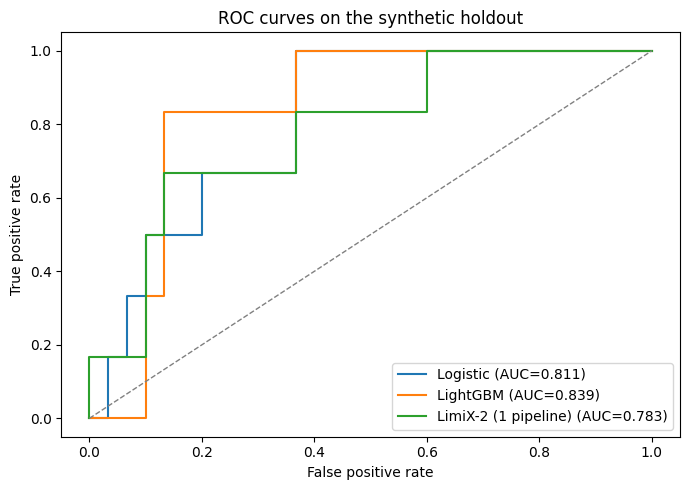

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, probabilities in scores.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probabilities):.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves on the synthetic holdout")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

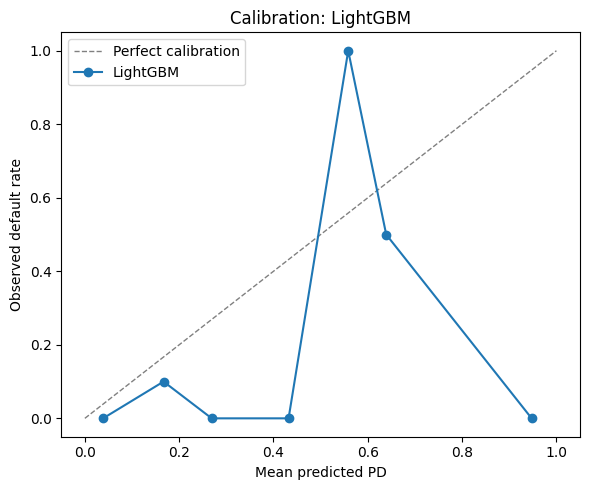

,bin_lower,bin_upper,count,mean_predicted,observed,gap
0,-0.001,0.125,14,0.039,0.0,-0.039
1,0.125,0.250,10,0.167,0.1,-0.067
2,0.250,0.375,2,0.269,0.0,-0.269
3,0.375,0.500,1,0.432,0.0,-0.432
4,0.500,0.625,3,0.558,1.0,0.442
5,0.625,0.750,4,0.639,0.5,-0.139
6,0.875,1.000,2,0.947,0.0,-0.947


In [6]:
best_name = metrics_frame.iloc[0]["model"]
best_probabilities = scores[best_name]
calibration = calibration_table(y_test, best_probabilities, n_bins=8)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1, label="Perfect calibration")
ax.plot(calibration["mean_predicted"], calibration["observed"], marker="o", label=best_name)
ax.set_xlabel("Mean predicted PD")
ax.set_ylabel("Observed default rate")
ax.set_title(f"Calibration: {best_name}")
ax.legend()
plt.tight_layout()
plt.show()

calibration.round(3)

## 5. Explain the riskiest application

Tree models use exact TreeSHAP. LimiX uses occlusion: replace one feature at a time with a reference value and measure the PD change. Reason codes are model-relative, not causal.

In [7]:
best_model = models[best_name]
order = np.argsort(-best_probabilities)[:3]
selected = X_test.iloc[order]
explanations = explain_model(best_model, selected, max_features=25)

for explanation in explanations:
    print(f"\nEntity {explanation.entity_id} | PD={explanation.prediction:.3f} | method={explanation.method}")
    for reason in explanation.reason_codes(4):
        print("  -", reason)


Entity SME0101 | PD=0.960 | method=tree_shap
  - Mean balance over the final 90 days (balance_last_90d_mean) increased predicted risk.
  - Mean absolute transaction amount (txn_amount_mean) increased predicted risk.
  - Share of revenue from the largest customer (revenue_top1_share) increased predicted risk.
  - Weighted composite of the four health scores (0-100) (cashflow_health_score) increased predicted risk.

Entity SME0069 | PD=0.934 | method=tree_shap
  - Mean balance over the final 90 days (balance_last_90d_mean) increased predicted risk.
  - Mean absolute transaction amount (txn_amount_mean) increased predicted risk.
  - Share of revenue from the largest customer (revenue_top1_share) increased predicted risk.
  - Customer receipts as a share of all inflows (inflow_quality) increased predicted risk.

Entity SME0111 | PD=0.643 | method=tree_shap
  - Mean balance over the final 90 days (balance_last_90d_mean) increased predicted risk.
  - Share of revenue from the largest custom

In [8]:
explanation = explanations[0]
explanation.top(8)[["feature", "value", "contribution", "direction", "description"]]

,feature,value,contribution,direction,description
0,balance_last_90d_mean,44575.516667,0.815461,increases risk,Mean balance over the final 90 days.
1,txn_amount_mean,3306.166179,0.631137,increases risk,Mean absolute transaction amount.
2,revenue_top1_share,0.069683,0.618364,increases risk,Share of revenue from the largest customer.
3,cashflow_health_score,71.398452,0.417643,increases risk,Weighted composite of the four health scores (...
4,cash_withdrawal_total,1687.450000,0.403807,increases risk,Total cash withdrawals.
5,recurring_counterparty_ratio,0.961235,0.378192,increases risk,Outflows to counterparties seen in three or mo...
6,distress_flag_count,3.000000,0.376032,increases risk,Count of triggered distress heuristics (0-8).
7,inflow_quality,0.989604,0.270549,increases risk,Customer receipts as a share of all inflows.


## 6. What to remember

* LimiX is competitive on small tabular samples but costs more latency than trees.
* A high AUC can hide poor calibration; report Brier and log loss.
* Explanations are decision support, not a causal claim or a complete adverse-action process.
* One CPU pipeline is a fast demo, not a leaderboard reproduction.

In [9]:
for model in models.values():
    if hasattr(model, "close"):
        model.close()
print("Released LimiX predictor memory.")

Released LimiX predictor memory.
